# Flood-response SoS analysis


In [21]:
from pathlib import Path
import json
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Find the project root when the notebook is launched from the project folder
# or from a child folder such as output/.
candidates = [Path.cwd(), *Path.cwd().parents]
project_dir = next(
    (path for path in candidates if (path / "output" / "simulation_runs.csv").exists()),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Could not find output/simulation_runs.csv from this notebook's working directory.")

output_dir = project_dir / "output"
runs_all = pd.read_csv(output_dir / "simulation_runs.csv")
flood_all = pd.read_csv(output_dir / "flood_history.csv")
with (output_dir / "simulation_summary.json").open(encoding="utf-8") as file:
    summary = json.load(file)

# Change this value to analyze another matched rescue-sensitivity condition.
selected_rescue_sensitivity = "boat_emphasis"
if "rescue_sensitivity" in runs_all.columns:
    available_sensitivities = set(runs_all["rescue_sensitivity"].dropna())
    if selected_rescue_sensitivity not in available_sensitivities:
        raise ValueError(
            f"Rescue-sensitivity condition {selected_rescue_sensitivity!r} is unavailable. "
            f"Available: {sorted(available_sensitivities)}"
        )
    runs = runs_all.loc[
        runs_all["rescue_sensitivity"] == selected_rescue_sensitivity
    ].copy()
    flood = flood_all.loc[
        flood_all["rescue_sensitivity"] == selected_rescue_sensitivity
    ].copy()
else:
    runs = runs_all.copy()
    flood = flood_all.copy()
    selected_rescue_sensitivity = "all available runs"

scenario_order = ["low_only", "high_only", "mixed"]
scenario_labels = {
    "low_only": "Low-only",
    "high_only": "High-only",
    "mixed": "Mixed",
}
scenario_colors = {
    "low_only": "#777777",
    "high_only": "#2878B5",
    "mixed": "#238B75",
}
scenario_line_styles = {"low_only": "-", "high_only": "--", "mixed": "-."}
configuration_order = ["reduced_departure", "baseline", "increased_departure"]
configuration_labels = {
    "reduced_departure": "Reduced",
    "baseline": "Baseline",
    "increased_departure": "Increased",
}
configuration_markers = {
    "reduced_departure": "o",
    "baseline": "s",
    "increased_departure": "^",
}

# Match the reference notebook's compact, paper-oriented matplotlib style.
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 8,
    "axes.titlesize": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

def format_axis(ax):
    ax.grid(axis="y", linewidth=0.3, alpha=0.5)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", pad=1.5)

plot_dir = project_dir / "plots"
plot_dir.mkdir(exist_ok=True)


## Victims rescued before deadline across runs


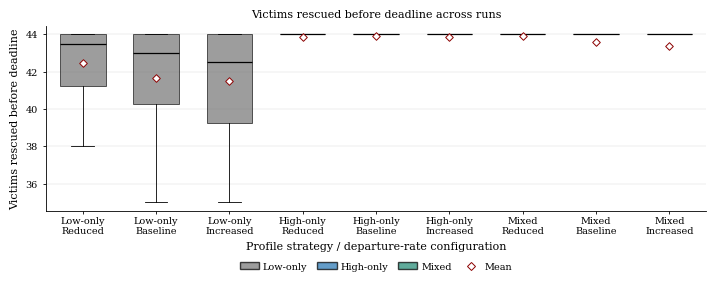

In [22]:
condition_order = [
    (strategy, configuration)
    for strategy in scenario_order
    for configuration in configuration_order
    if ((runs["scenario"] == strategy) & (runs["profile_configuration"] == configuration)).any()
]
condition_values = [
    runs.loc[
        (runs["scenario"] == strategy)
        & (runs["profile_configuration"] == configuration),
        "victims_rescued_before_deadline",
    ].dropna().to_numpy()
    for strategy, configuration in condition_order
]
condition_labels = [
    f"{scenario_labels[strategy]}\n{configuration_labels.get(configuration, configuration)}"
    for strategy, configuration in condition_order
]

fig, ax = plt.subplots(figsize=(7.2, 3.0))
box = ax.boxplot(
    condition_values,
    patch_artist=True,
    showfliers=False,
    widths=0.62,
    medianprops={"color": "black", "linewidth": 0.9},
    whiskerprops={"color": "black", "linewidth": 0.6},
    capprops={"color": "black", "linewidth": 0.6},
)
for patch, (strategy, _) in zip(box["boxes"], condition_order):
    patch.set_facecolor(scenario_colors[strategy])
    patch.set_edgecolor("black")
    patch.set_linewidth(0.6)
    patch.set_alpha(0.72)

means = [values.mean() if len(values) else np.nan for values in condition_values]
ax.scatter(
    np.arange(1, len(means) + 1), means,
    marker="D", s=15, facecolor="white", edgecolor="darkred", linewidth=0.7,
    zorder=4,
)
ax.set_xticks(np.arange(1, len(condition_labels) + 1))
ax.set_xticklabels(condition_labels)
ax.set_xlabel("Profile strategy / departure-rate configuration")
ax.set_ylabel("Victims rescued before deadline")
ax.set_title("Victims rescued before deadline across runs")
format_axis(ax)
legend_handles = [
    Patch(facecolor=scenario_colors[strategy], edgecolor="black", alpha=0.72,
          label=scenario_labels[strategy])
    for strategy in scenario_order if strategy in runs["scenario"].unique()
]
legend_handles.append(
    Line2D([0], [0], marker="D", color="darkred", markerfacecolor="white",
           markeredgewidth=0.7, linestyle="None", markersize=4, label="Mean")
)
ax.legend(handles=legend_handles, frameon=False, ncol=4, loc="upper center",
          bbox_to_anchor=(0.5, -0.23), columnspacing=1.0, handletextpad=0.4)
fig.tight_layout()
fig.savefig(plot_dir / "victims_rescued_across_runs.pdf", bbox_inches="tight")
plt.show()


## Flood trajectory


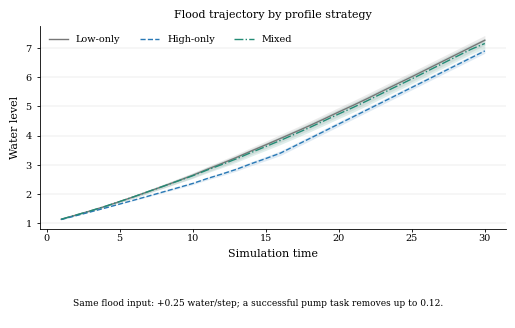

In [26]:
flood_stats = (
    flood.groupby(["scenario", "time"], observed=True)["water_level"]
    .agg(mean="mean", std="std", count="count")
    .reset_index()
)
fig, ax = plt.subplots(figsize=(5.2, 3.25))
for strategy in scenario_order:
    part = flood_stats.loc[flood_stats["scenario"] == strategy].sort_values("time")
    if part.empty:
        continue
    ci = 1.96 * part["std"].fillna(0) / np.sqrt(part["count"].clip(lower=1))
    ax.plot(part["time"], part["mean"], color=scenario_colors[strategy],
            linestyle=scenario_line_styles[strategy], linewidth=1.0,
            label=scenario_labels[strategy])
    ax.fill_between(part["time"], part["mean"] - ci, part["mean"] + ci,
                    color=scenario_colors[strategy], alpha=0.14, linewidth=0)
ax.set_xlabel("Simulation time")
ax.set_ylabel("Water level")
ax.set_title("Flood trajectory by profile strategy")
format_axis(ax)
ax.legend(frameon=False, ncol=3, loc="upper left")
fig.tight_layout(rect=(0, 0.16, 1, 1))
fig.text(
    0.5, 0.015,
    "Same flood input: +0.25 water/step; a successful pump task removes up to 0.12.\n",
    ha="center", va="bottom", fontsize=6.5,
)
fig.savefig(plot_dir / "flood_trajectory.pdf", bbox_inches="tight")
plt.show()


## Victims rescued before deadline over time


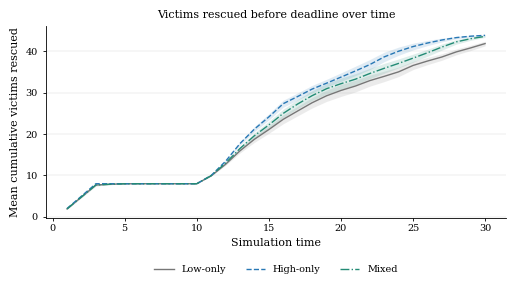

In [24]:
rescue_stats = (
    flood.groupby(["scenario", "time"], observed=True)["victims_rescued_before_deadline"]
    .agg(mean="mean", std="std", count="count")
    .reset_index()
)
fig, ax = plt.subplots(figsize=(5.2, 3.0))
for strategy in scenario_order:
    part = rescue_stats.loc[rescue_stats["scenario"] == strategy].sort_values("time")
    if part.empty:
        continue
    ci = 1.96 * part["std"].fillna(0) / np.sqrt(part["count"].clip(lower=1))
    ax.plot(part["time"], part["mean"], color=scenario_colors[strategy],
            linestyle=scenario_line_styles[strategy], linewidth=1.0,
            label=scenario_labels[strategy])
    ax.fill_between(part["time"], part["mean"] - ci, part["mean"] + ci,
                    color=scenario_colors[strategy], alpha=0.14, linewidth=0)
ax.set_xlabel("Simulation time")
ax.set_ylabel("Mean cumulative victims rescued")
ax.set_title("Victims rescued before deadline over time")
format_axis(ax)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2))
fig.tight_layout()
fig.savefig(plot_dir / "victims_rescued_over_time.pdf", bbox_inches="tight")
plt.show()


## Mission success versus mean base cost


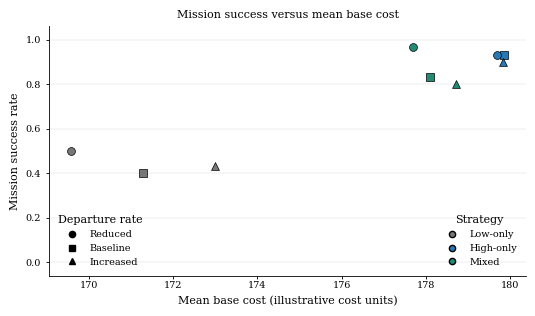

In [25]:
# Use the scenario/configuration aggregates stored in simulation_summary.json.
summary_rows = []
for condition, values in summary.get("aggregates", {}).items():
    parts = condition.split("/")
    if len(parts) != 3:
        continue
    strategy, configuration, sensitivity = parts
    if sensitivity != selected_rescue_sensitivity:
        continue
    summary_rows.append({
        "scenario": strategy,
        "profile_configuration": configuration,
        "success_rate": values["success_rate"],
        "mean_cost_base": values["mean_cost_base"],
    })

cost_summary = pd.DataFrame(summary_rows)
if cost_summary.empty:
    raise ValueError("No matching conditions found in simulation_summary.json for the selected sensitivity.")
cost_unit = summary.get("experiment", {}).get("cost_model", {}).get(
    "cost_unit", "cost units"
)

fig, ax = plt.subplots(figsize=(5.4, 3.2))
for _, row in cost_summary.iterrows():
    ax.scatter(
        row["mean_cost_base"], row["success_rate"],
        marker=configuration_markers.get(row["profile_configuration"], "o"),
        color=scenario_colors.get(row["scenario"], "black"),
        edgecolor="black", linewidth=0.5, s=32, zorder=3,
    )
ax.set_xlabel(f"Mean base cost ({cost_unit})")
ax.set_ylabel("Mission success rate")
ax.set_ylim(-0.06, 1.06)
ax.set_title("Mission success versus mean base cost")
format_axis(ax)
scenario_handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor=scenario_colors[s],
           markeredgecolor="black", markersize=4.5, label=scenario_labels[s])
    for s in scenario_order if s in cost_summary["scenario"].unique()
]
configuration_handles = [
    Line2D([0], [0], marker=configuration_markers[c], color="black", linestyle="None",
           markersize=4.5, label=configuration_labels[c])
    for c in configuration_order if c in cost_summary["profile_configuration"].unique()
]
first_legend = ax.legend(handles=scenario_handles, title="Strategy", frameon=False,
                         loc="lower right", ncol=1)
ax.add_artist(first_legend)
ax.legend(handles=configuration_handles, title="Departure rate", frameon=False,
          loc="lower left", ncol=1)
fig.tight_layout()
fig.savefig(plot_dir / "mission_success_vs_mean_base_cost.pdf", bbox_inches="tight")
plt.show()
